# Final checks

Collection of robustness checks for the paper. Sections:

1. **Aliasing in the bias-field pipeline** (operator construction + CIC deposit)
2. **Phase-matched muchisimocks vs. SHAMe** (cosmic-variance-free comparison)

In [1]:
import sys
from pathlib import Path

try:
    REPO_ROOT = Path(__file__).resolve().parents[1]
except NameError:
    REPO_ROOT = Path.cwd()
    if REPO_ROOT.name == "notebooks":
        REPO_ROOT = REPO_ROOT.parent

sys.path.insert(0, str(REPO_ROOT / "code"))
sys.path.insert(0, str(REPO_ROOT / "code_auxiliary"))

import numpy as np
from matplotlib import pyplot as plt

import paths

%load_ext autoreload
%autoreload 2

## 1. Aliasing in the bias-field pipeline

How `data_creation_pipeline` builds one mock's operator fields (box $L = 1000\,h^{-1}$Mpc):

| step | grid | Nyquist $k_N=\pi N/L$ [$h$/Mpc] |
|---|---|---|
| 1. Linear field, smoothed at `damping_scale` $=0.75\,h$/Mpc; Lagrangian operators $\{1,\delta,\delta^2,s^2,\nabla^2\delta\}$ built on the particle grid | $512^3$ particles | 1.61 |
| 2. map2map moves the $512^3$ particles to their nonlinear positions | $512^3$ particles | — |
| 3. CIC **deposit** of the operator-weighted particles onto a mesh (`bacco.statistics.compute_mesh(ngrid=...)`) | deposit mesh $512^3$ | 1.61 |
| 4. **$k$-cut**: keep only modes of a $128^3$ grid | $128^3$ | 0.40 |
| 5. **Deconvolve** the CIC window of the $512^3$ deposit mesh | $128^3$ | — |

Two questions: **(1)** does building the operators (products of fields, step 1) alias? **(2)** does the deposit (step 3) alias, and is the deconvolution (step 5) exact?

### 1.1 Operators: no aliasing, by Orszag's rule

A product of two fields has power up to the sum of their wavenumbers; anything above $k_N$ wraps back. Orszag's 2/3 rule says products are alias-free if the fields are zero above $\tfrac23 k_N = 1.07\,h$/Mpc. The smoothing at $0.75$ acts as that zero padding: in bacco it is a near-sharp cut, $P(k)\to P(k)\cdot\tfrac12\,\mathrm{erfc}[\log_{10}(k/0.75)/0.01]$ (`lss_scaler/lssmodule.c`), so $\delta$ has no power above $0.75$. The quadratic operators then reach at most $1.5 < k_N = 1.61$, so nothing wraps at all, which is stronger than the 2/3 condition. No test needed.

### 1.2 Deposit and deconvolution: test with a finer deposit mesh

The particles in step 3 sit at nonlinear positions and are not band-limited, so the CIC deposit can fold power from above $k_N$ into our band, and dividing by the CIC window in step 5 cannot undo that.

**Test** (`code/test_deposit_aliasing.py`, on `muchisimocks_lib_p5_n10000_rerun/LH0`, the one mock with map2map displacements saved): keep the $512^3$ particles, positions and operator weights fixed, and change only the **deposit mesh** in step 3: $256^3$, $512^3$ (production) and $1024^3$ (reference, $k_N = 3.22$). Each is then $k$-cut to $128^3$ and deconvolved with its own deposit mesh's CIC window, exactly as in steps 4–5. If the deposit and deconvolution are fine, the three should give the same $P(k)$.

$P(k)$ is measured as in production: `compute_statistics.compute_pk`, 32 log bins from 0.01 to 0.4 $h$/Mpc, in $h^{-3}$Mpc$^3$ (`code_auxiliary/aliasing_pk_production_bins.py`). The grey band marks bins beyond the fiducial cut (`_kp0.37`). Shown for the tracer field (SHAMe-like biases, $\bar n = 2.2\times10^{-4}$). Each operator alone behaves the same way (max values are in the table).

In [2]:

dir_alias = paths.DIR_DATA / "aliasing_test" / "LH0"
# P(k) of the test fields measured with production's compute_pk (32 log bins, (Mpc/h)^3),
# written by code_auxiliary/aliasing_pk_production_bins.py
res = dict(np.load(dir_alias / "pk_production_bins.npz"))
k = res["k"]
# field-level check that the test reproduces the production field (code/test_deposit_aliasing.py)
pdiff_production = np.load(dir_alias / "summary.npz")["pdiff_tracer_production_vs_ng512"].max()

L_BOX = 1000.
ops = ["1", "delta", "delta2", "s2", "nabla2delta"]
ref = "ng1024"
cfgs = ["ng512", "ng256"]
n_dep = {"ng256": 256, "ng512": 512, "ng1024": 1024}
cfg_labels = {c: rf"deposit ${n}^3$ → $k$-cut $128^3$ → deconvolve ${n}^3$ CIC" for c, n in n_dep.items()}
cfg_labels["ng512"] += " (production)"
cfg_labels["ng1024"] += " (reference)"
cfg_colors = {"ng256": "C3", "ng512": "C0", "ng1024": "k"}
cfg_ls = {"ng256": ":", "ng512": "--", "ng1024": "-"}
cfg_lw = {"ng256": 2.5, "ng512": 2.5, "ng1024": 1.2}
# Gaussian (cosmic-variance) error of one production P(k) bin in one (1 Gpc/h)^3 box: sqrt(2/N_modes)
kf = 2 * np.pi / L_BOX
edges = np.logspace(np.log10(0.01), np.log10(0.4), 33)  # production P(k) bin edges (compute_pk defaults)
n_modes = 4 * np.pi / 3 * (edges[1:]**3 - edges[:-1]**3) / kf**3
sigma_frac = np.sqrt(2 / n_modes)
assert len(sigma_frac) == len(k)

kmax_analysis = 0.37  # v2 fiducial P(k) cut (_kp0.37): bins with top edge <= 0.37
k_cut_edge = edges[1:][edges[1:] <= kmax_analysis].max()  # top edge of the last kept bin



def resid(field, cfg):
    return np.abs(res[f"pk_{field}_{cfg}"] / res[f"pk_{field}_{ref}"] - 1)

In [3]:
m = edges[1:] <= kmax_analysis  # v2 cut convention: keep bins whose top edge <= kmax
print(f"max |P/P_ref - 1| over production bins with k <= {kmax_analysis} h/Mpc; P_ref = deposit 1024^3")
print(f"{'':<36s}" + "".join(f"{f'deposit {n_dep[c]}^3':>15s}" for c in cfgs))
print(f"{'tracer':<36s}" + "".join(f"{resid('tracer', c)[m].max():15.1e}" for c in cfgs))
print(f"{'worst single operator':<36s}" + "".join(f"{max(resid(op, c)[m].max() for op in ops):15.1e}" for c in cfgs))
print(f"{'Gaussian error of one bin, one box':<36s}{sigma_frac[m].min():15.1e}   (smallest, at k = {k[m][-1]:.2f})")
print(f"\nThis test's deposit-512^3 field vs the production field: P(f - f_prod)/P = {pdiff_production:.0e} "
      "(the test runs the pipeline's code)")

max |P/P_ref - 1| over production bins with k <= 0.37 h/Mpc; P_ref = deposit 1024^3
                                      deposit 512^3  deposit 256^3
tracer                                      2.5e-05        5.3e-04
worst single operator                       1.5e-04        2.2e-03
Gaussian error of one bin, one box          3.0e-03   (smallest, at k = 0.34)

This test's deposit-512^3 field vs the production field: P(f - f_prod)/P = 4e-14 (the test runs the pipeline's code)


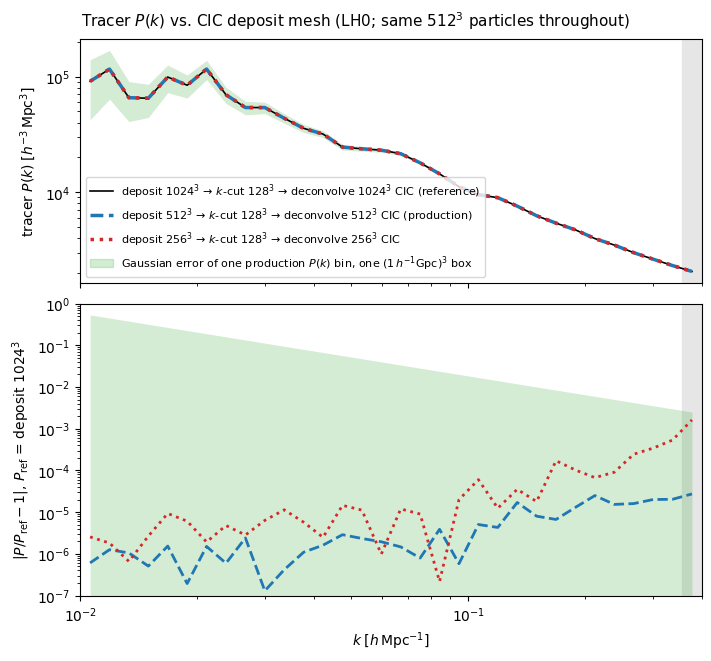

In [4]:
# Colour and line style = deposit mesh, in both panels. Shaded green = Gaussian error of one bin in one box.
from matplotlib.patches import Patch

color_err = "C2"
fig, (ax_p, ax_r) = plt.subplots(2, 1, figsize=(7, 6.5), sharex=True,
                                 gridspec_kw=dict(height_ratios=[1, 1.2]), layout="constrained")
p_ref = res[f"pk_tracer_{ref}"]
ax_p.fill_between(k, p_ref * (1 - sigma_frac), p_ref * (1 + sigma_frac), color=color_err, alpha=0.2, lw=0)
for c in [ref] + cfgs:
    ax_p.plot(k, res[f"pk_tracer_{c}"], color=cfg_colors[c], ls=cfg_ls[c], lw=cfg_lw[c], label=cfg_labels[c])
ax_p.set_yscale("log")
ax_p.set_ylabel(r"tracer $P(k)\;[h^{-3}\,\mathrm{Mpc}^{3}]$")
handles, _ = ax_p.get_legend_handles_labels()
handles.append(Patch(color=color_err, alpha=0.2,
                     label=r"Gaussian error of one production $P(k)$ bin, one $(1\,h^{-1}\mathrm{Gpc})^3$ box"))
ax_p.legend(handles=handles, fontsize=8)

ax_r.fill_between(k, 1e-7, sigma_frac, color=color_err, alpha=0.2, lw=0)
for c in cfgs:
    ax_r.plot(k, resid("tracer", c), color=cfg_colors[c], ls=cfg_ls[c], lw=2)
ax_r.set_yscale("log")
ax_r.set_ylim(1e-7, 1)
ax_r.set_xlabel(r"$k\;[h\,\mathrm{Mpc}^{-1}]$")
ax_r.set_ylabel(r"$|P/P_\mathrm{ref}-1|$, $P_\mathrm{ref}$ = deposit $1024^3$")
for ax in (ax_p, ax_r):
    ax.axvspan(k_cut_edge, edges[-1], color="0.9", zorder=0)
    ax.set_xscale("log")
    ax.set_xlim(edges[0], edges[-1])
fig.suptitle(r"Tracer $P(k)$ vs. CIC deposit mesh (LH0; same $512^3$ particles throughout)", fontsize=11)
plt.show()

**Summary**
- **Operators (question 1): no aliasing.** The linear field is smoothed at $0.75\,h$/Mpc, so the quadratic operators built on the $512^3$ particle grid have no power above $1.5\,h$/Mpc, below its Nyquist frequency of $1.61\,h$/Mpc. Nothing wraps, which is stronger than Orszag's 2/3 rule.
- **Deposit (question 2): aliasing is negligible.** Depositing the same $512^3$ particles on a $1024^3$ mesh instead of the production $512^3$ mesh changes the tracer $P(k)$ by at most $3\times10^{-5}$ over the production bins with $k \le 0.37\,h$/Mpc (each operator: at most $1.5\times10^{-4}$). The Gaussian error of one bin in one box is at least $3\times10^{-3}$, about 100× larger.
- **Deconvolution: effectively exact.** Each mesh is deconvolved with its own CIC window, and the windows differ by several percent at our highest $k$. After deconvolution the $512^3$ and $1024^3$ results still agree to the level above, so the deconvolution removes the window exactly up to the aliasing.
- **The test is sensitive.** The coarser $256^3$ deposit is ~20× worse and grows with $k$, as aliasing should.
- **Caveat:** one mock (LH0, $\sigma_8 = 0.70$). Cosmologies with higher $\sigma_8$ have more small-scale power and will alias somewhat more.

## 2. Phase-matched muchisimocks vs. SHAMe

The SHAMe high-fidelity mock lives on the BACCO "Rings" paired-and-fixed run (Planck, $L=1024\,h^{-1}$Mpc, $3072^3$, phases $0$ and $\pi$). Using the Rings seed **$-406168$** (verified with `make_shame_matched_mock.py check_seed`: the $132^3$ linear field correlates with the SHAMe $z=0$ matter mesh at $r>0.98$ for $k<0.05$, both phases; seed $0$ gives $r\approx0$), we regenerated the muchisimocks bias-operator fields with **identical initial conditions**: `make_shame_matched_mock.py make --seed -406168` (box 1024, $524^3 \to 132^3$, fixed amplitude, `phase_type=1`). Output: `muchisimocks_lib_ood/shame_matched/phase{0,pi}_seed-406168/`.

Because both share the same phases, the deterministic part of the comparison is free of sample variance and can be done mode by mode. Real space throughout (the SHAMe meshes are real space).

- **2.1** Grids and box size.
- **2.2** Fields: matter and tracer maps, biases fit at field level, and the residual stochasticity.
- **2.3** Summary statistics $P$, $P_{gm}$, $B$ at all three SHAMe densities, with noise amplitudes fit on this mock.
- **2.4** The fitted noise amplitudes vs. density, against the priors.
- **2.5** Does $B$ need an extra $\epsilon^2$ noise term?

#### Bias convention: $b_2$, $b_{s^2}$ divided by 2

The SHAMe biases come from the probabilistic Lagrangian estimators of Stücker et al. 2024 (arXiv:2405.01950), which write $F = 1 + b_1\delta + \tfrac12 b_2\delta^2 + \dots$. Our (bacco) operators are $\delta^2$ and $s^2$ with no $\tfrac12$, so `utils_model.bias_dict_shame` stores the delivered $b_2$ and $b_{s^2}$ **divided by 2** (confirmed with the person who measured them, 2026-11-15). All "SHAMe biases" in this notebook use this convention.

(Before 2026-11-15 the code multiplied them by 2 instead. The phase-matched tests below were what flagged it: the ×2 values gave too much small-scale power, e.g. a cross ratio $P_{\mathrm{SHAMe}\times\mathrm{model}}/P_\mathrm{model}$ of 0.86 vs 0.92 for ÷2 at $k=0.35$, $\bar n=2.2\times10^{-4}$, and a $P_{gm}$ reduced $\chi^2$ of 17.5 vs 4.4 in §2.5.)

### 2.1 Grids and box size

Everything in this comparison uses **box $L = 1024\,h^{-1}$Mpc**, the SHAMe/Rings box. It has to: the phases are only identical mode by mode if the Fourier grid ($k_f = 2\pi/1024$) is the same as the simulation's.

| | deposit grid | cell [$h^{-1}$Mpc] | target grid (k-cut) | cell [$h^{-1}$Mpc] | $k_N$ of target [$h$/Mpc] |
|---|---|---|---|---|---|
| muchisimocks library ($L=1000$) | $512^3$ | 1.953 | $128^3$ | 7.813 | 0.402 |
| matched muchisimocks ($L=1024$) | $524^3$ | 1.954 | $132^3$ | 7.758 | 0.405 |
| SHAMe tracer & matter ($L=1024$) | $524^3$ | 1.954 | $132^3$ | 7.758 | 0.405 |

- **matched vs. SHAMe:** identical grids, identical pipeline (CIC deposit on $524^3$ → $k$-cut to $132^3$ → CIC deconvolution, `process_mock_catalogs.py`), so the fields can be compared cell by cell.
- **matched vs. library:** the deposit cell (map2map's operating scale) matches to $0.07\%$. The target cell is $0.7\%$ smaller because $1024/7.8125 = 131.07$ is rounded to the nearest even integer (`round_to_nearest_even`). That only moves the $k$-cut/Nyquist from $0.402$ to $0.405\,h$/Mpc, above our $k_\mathrm{max}=0.35$. All statistics are binned in physical $k$ with the same edges ($0.01$–$0.4$), so the data vectors line up.
- Particle resolution is the one thing that does not match: map2map moves $524^3$ particles, the Rings run has $3072^3$.

In [5]:
import utils_model
import make_shame_matched_mock as msm

L_SH = msm.BOX_SIZE            # 1024
NG_SH = msm.N_GRID_TARGET      # 132
SEED_SH = -406168
dir_matched = paths.mocks_lib_ood_dir(msm.SUBDIR_OOD)
tags_shame = ['_nbar0.00011', '_nbar0.00022', '_nbar0.00054']
phases_sh = ['0', 'pi']
kmax_fit = 0.2

def _kgrid(n, L):
    kf = 2 * np.pi / L
    kx = np.fft.fftfreq(n, d=1. / n) * kf
    kz = np.fft.rfftfreq(n, d=1. / n) * kf
    return np.sqrt(kx[:, None, None]**2 + kx[None, :, None]**2 + kz[None, None, :]**2)

KMAG_SH = _kgrid(NG_SH, L_SH)
_edges = np.arange(0.5, NG_SH // 2) * 2 * np.pi / L_SH      # dk = k_f
k_sh = 0.5 * (_edges[1:] + _edges[:-1])
_idx = np.digitize(KMAG_SH.ravel(), _edges) - 1
_ok = (_idx >= 0) & (_idx < len(k_sh))
_w = np.full(KMAG_SH.shape, 2.0); _w[..., 0] = 1; _w[..., -1] = 1   # rfft half-plane weights
_w = _w.ravel()[_ok]
_nmode = np.bincount(_idx[_ok], _w, len(k_sh))

def ft_sh(field):
    return np.fft.rfftn(field - field.mean()) * (L_SH / NG_SH)**3

def pk_sh(fa, fb=None):
    fb = fa if fb is None else fb
    p = (fa * np.conj(fb)).real.ravel()[_ok] * _w
    return np.bincount(_idx[_ok], p, len(k_sh)) / _nmode / L_SH**3

def load_matched_ops(phase):
    fn = dir_matched / f'phase{phase}_seed{SEED_SH}' / f'bias_fields_eul_deconvolved_{SEED_SH}.npy'
    ops = np.load(fn).astype(np.float64)
    return ops / ops[0].mean()     # O_1 -> 1 + delta_m; same factor for all operators (= get_tracer_field with n_grid_norm=524)

def load_shame_fields(phase, tag):
    tracer = np.load(msm.DIR_DATA_SHAME / f'data{tag}' / f'tracer_field_phase{phase}.npy') * NG_SH**3  # stored as delta/132^3
    dens = np.load(msm.DIR_DATA_SHAME / f'dens_mesh_phase{phase}.npy')
    return tracer, dens / dens.mean() - 1

def fit_bias_fieldlevel(ops_k, tk, kmax):
    m = (KMAG_SH <= kmax) & (KMAG_SH > 0)
    y = (tk - ops_k[0])[m]
    A = np.stack([o[m] for o in ops_k[1:]], axis=1)
    b, *_ = np.linalg.lstsq(np.concatenate([A.real, A.imag]), np.concatenate([y.real, y.imag]), rcond=None)
    return b

# noise amplitudes fit on this mock for every SHAMe density (code_auxiliary/select_shame_noisebest.py fit)
fit_nb = np.load(msm.DIR_DATA_SHAME / f'matched_seed{SEED_SH}' / 'noisebest_select' / 'fit.npy', allow_pickle=True).item()
names_nb, bounds_nb = fit_nb['noise_names'], fit_nb['bounds_A']
nbar_of = {t: float(t.split('nbar')[1]) for t in tags_shame}
# (color, linestyle, marker, label) per bias choice, shared by the 2.3 and 2.4 figures
settings_nb = {'fixed b': ('C3', '-', 'o', 'phase-matched muchisimocks model:\nSHAMe biases + fitted noise'),
               'free b':  ('C0', '--', '^', 'phase-matched muchisimocks model:\nfree biases + fitted noise')}

### 2.2 Fields

Three checks at field level:

- **(a) Matter:** map2map $\mathcal{O}_1 = 1+\delta_m$ vs. the N-body matter mesh.
- **(b) Tracer, deterministic part:** $\delta_t^\mathrm{model} = \delta_m + b_1\delta + b_2\delta^2 + b_{s^2}s^2 + b_{\nabla^2}\nabla^2\delta$ with (i) the SHAMe biases `utils_model.bias_dict_shame` and (ii) biases fit at field level to each SHAMe catalog ($k\le0.2$, least squares over modes), compared with $P_\mathrm{SHAMe} - 1/\bar n$.
- **(c) Stochasticity:** $P_\mathrm{err}(k) = P(\delta_\mathrm{SHAMe} - \delta_t^\mathrm{model})$ in units of Poisson $1/\bar n$; this is what the noise model has to describe.

$P(k)$ here is a plain numpy FFT estimator with $\Delta k = k_f$ (so auto, cross and residual spectra are binned identically); it agrees with the stored bacco SHAMe $P(k)$ to $<1\%$ except in the first couple of (differently binned) $k$ bins.

In [6]:
res_sh = {}
for phase in phases_sh:
    ops_k = [ft_sh(o) for o in load_matched_ops(phase)]
    _, dm = load_shame_fields(phase, tags_shame[0])
    dm_k = ft_sh(dm)
    p_m2m, p_nb = pk_sh(ops_k[0]), pk_sh(dm_k)
    res_sh[('matter', phase)] = dict(ratio=p_m2m / p_nb, r=pk_sh(ops_k[0], dm_k) / np.sqrt(p_m2m * p_nb))
    for tag in tags_shame:
        tk = ft_sh(load_shame_fields(phase, tag)[0])
        nbar = float(tag.split('nbar')[1])
        b_dict = np.array([utils_model.bias_dict_shame[tag][n] for n in utils_model.biasparam_names_ordered])
        b_fit = fit_bias_fieldlevel(ops_k, tk, kmax_fit)
        p_t = pk_sh(tk)
        out = dict(nbar=nbar, p_shame=p_t)
        for lab, b in [('dict', b_dict), ('fit', b_fit)]:
            mk = ops_k[0] + sum(bi * o for bi, o in zip(b, ops_k[1:]))
            p_m = pk_sh(mk)
            out[lab] = dict(b=b, p_model=p_m,
                            ratio_sn=(p_t - 1 / nbar) / p_m,
                            r=pk_sh(tk, mk) / np.sqrt(p_t * p_m),
                            perr_nbar=pk_sh(tk - mk) * nbar)
        res_sh[(tag, phase)] = out

# paired-fixed: average the two phases
def pmean(key, *sub):
    vals = []
    for ph in phases_sh:
        v = res_sh[(key, ph)]
        for s in sub:
            v = v[s]
        vals.append(v)
    return np.mean(vals, axis=0)

ksel = [0.05, 0.1, 0.2, 0.3, 0.35]
isel = [np.argmin(np.abs(k_sh - kk)) for kk in ksel]
print('k =', np.round(k_sh[isel], 3))
print(f"(a) matter  P_m2m/P_Nbody : {np.round(pmean('matter', 'ratio')[isel], 3)}   r : {np.round(pmean('matter', 'r')[isel], 3)}")
names = utils_model.biasparam_names_ordered
for tag in tags_shame:
    print(f'\n{tag}')
    for lab in ['dict', 'fit']:
        b = pmean(tag, lab, 'b')
        print(f"  [{lab:4s}] b = " + ", ".join(f'{n}={v:+.3f}' for n, v in zip(names, b)))
        print(f"         (P_shame-1/nbar)/P_model : {np.round(pmean(tag, lab, 'ratio_sn')[isel], 3)}")
        print(f"         r(shame, model)          : {np.round(pmean(tag, lab, 'r')[isel], 3)}")
        print(f"         P_err * nbar             : {np.round(pmean(tag, lab, 'perr_nbar')[isel], 3)}")

k = [0.049 0.098 0.202 0.301 0.35 ]
(a) matter  P_m2m/P_Nbody : [0.998 0.998 0.991 0.995 0.994]   r : [0.997 0.996 0.987 0.973 0.963]

_nbar0.00011
  [dict] b = b1=+0.529, b2=+0.069, bs2=-0.109, bl=-1.070
         (P_shame-1/nbar)/P_model : [0.941 0.93  0.901 0.801 0.788]
         r(shame, model)          : [0.875 0.785 0.641 0.555 0.523]
         P_err * nbar             : [0.967 0.966 0.972 0.97  0.978]
  [fit ] b = b1=+0.513, b2=+0.041, bs2=-0.078, bl=-0.293
         (P_shame-1/nbar)/P_model : [0.968 0.97  0.977 0.897 0.895]
         r(shame, model)          : [0.874 0.785 0.641 0.555 0.523]
         P_err * nbar             : [0.965 0.964 0.971 0.968 0.975]

_nbar0.00022
  [dict] b = b1=+0.474, b2=+0.032, bs2=-0.085, bl=-0.824
         (P_shame-1/nbar)/P_model : [0.95  0.932 0.936 0.86  0.831]
         r(shame, model)          : [0.924 0.862 0.748 0.663 0.629]
         P_err * nbar             : [0.996 0.973 0.969 0.978 0.984]
  [fit ] b = b1=+0.457, b2=+0.011, bs2=-0.068, bl=-0.23

**Maps** (phase 0, $\bar n = 2.2\times10^{-4}$, a $31\,h^{-1}$Mpc slab). Rows: matter; tracer with the SHAMe biases plus the best-fit noise of §2.3 (one noise realization, the first one used in the fit).

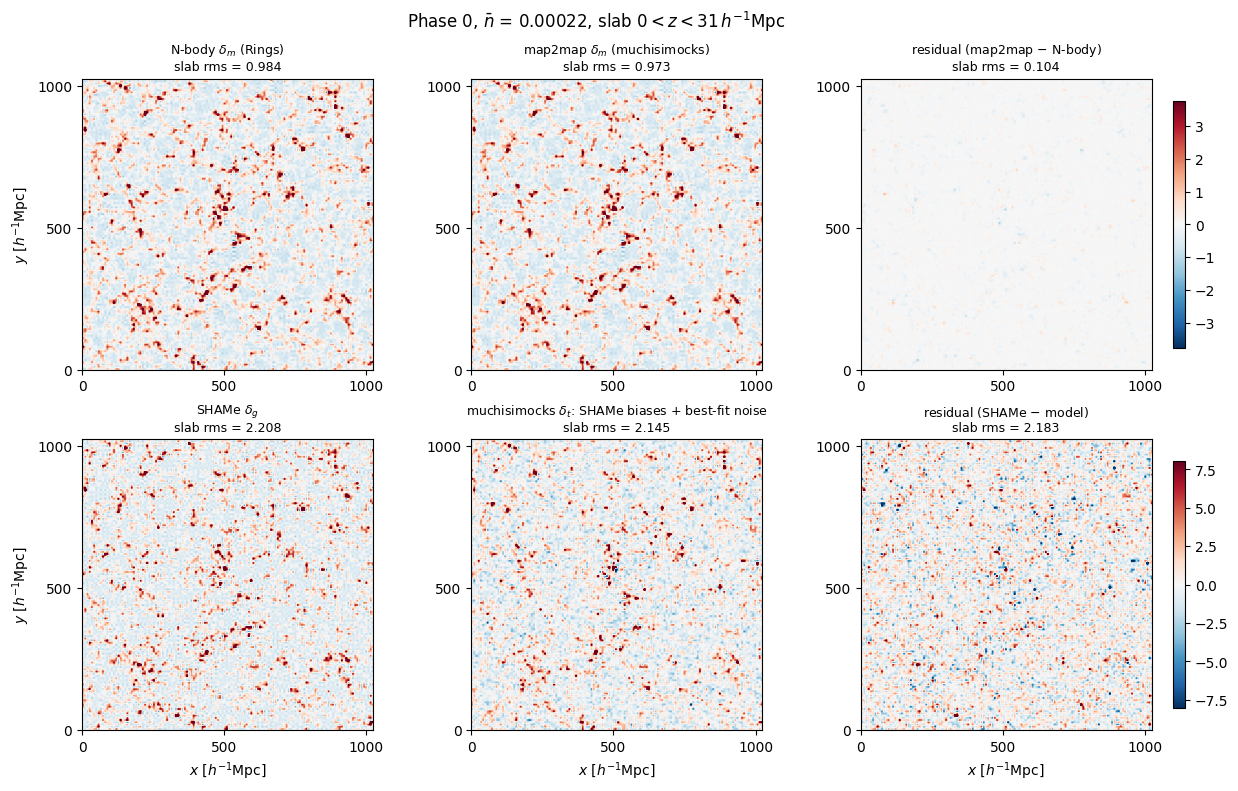

cell-level rms (full box):  SHAMe 4.037   model no noise 2.770   model + noise 4.040
                            residual no noise 3.106   residual + noise 4.269


In [7]:
phase_show, tag_show = '0', '_nbar0.00022'
nslab = 4                                  # slab thickness in cells (4 x 7.76 = 31 Mpc/h)
cell = L_SH / NG_SH

ops_show = load_matched_ops(phase_show)
t_shame, dm_nbody = load_shame_fields(phase_show, tag_show)
dm_m2m = ops_show[0] - 1
fit_show = fit_nb['fits'][(tag_show, 'fixed b')]
b_show = fit_show['b']                                       # = bias_dict_shame[tag_show]
A_show = fit_show['A_lib'] * fit_nb['V_scale']               # amplitudes on the matched 132^3 grid
eps_show = np.random.default_rng(40000).standard_normal(ops_show[0].shape)   # noise realization 0 of the fit
t_det = dm_m2m + sum(b * o for b, o in zip(b_show, ops_show[1:]))
t_noisy = t_det + eps_show * sum(a * o for a, o in zip(A_show, ops_show))     # multiplicative noise model

def slab(f):
    return f[:, :, :nslab].mean(axis=-1)

rows = [
    ([r'N-body $\delta_m$ (Rings)', r'map2map $\delta_m$ (muchisimocks)', 'residual (map2map $-$ N-body)'],
     [dm_nbody, dm_m2m, dm_m2m - dm_nbody]),
    ([r'SHAMe $\delta_g$', r'muchisimocks $\delta_t$: SHAMe biases + best-fit noise', 'residual (SHAMe $-$ model)'],
     [t_shame, t_noisy, t_shame - t_noisy]),
]
vmax_row = [np.percentile(np.abs(slab(dm_nbody)), 99), np.percentile(np.abs(slab(t_shame)), 99)]
fig, axes = plt.subplots(len(rows), 3, figsize=(12.5, 3.9 * len(rows)), layout='constrained')
ext = [0, L_SH, 0, L_SH]
for (titles, fs), vmax, axrow in zip(rows, vmax_row, axes):
    for f, ttl, ax in zip(fs, titles, axrow):
        im = ax.imshow(slab(f).T, origin='lower', extent=ext, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
        ax.set_title(ttl + f'\nslab rms = {slab(f).std():.3f}', fontsize=9)
        ax.set_xticks([0, 500, 1000]); ax.set_yticks([0, 500, 1000])
    fig.colorbar(im, ax=axrow, shrink=0.85, pad=0.01)
    axrow[0].set_ylabel(r'$y$ [$h^{-1}$Mpc]')
for ax in axes[-1]:
    ax.set_xlabel(r'$x$ [$h^{-1}$Mpc]')
fig.suptitle(rf'Phase {phase_show}, $\bar n$ = {tag_show[5:]}, slab $0<z<{nslab * cell:.0f}\,h^{{-1}}$Mpc')
plt.show()
print(f'cell-level rms (full box):  SHAMe {t_shame.std():.3f}   model no noise {t_det.std():.3f}   model + noise {t_noisy.std():.3f}')
print(f'                            residual no noise {(t_shame - t_det).std():.3f}   residual + noise {(t_shame - t_noisy).std():.3f}')

**Conclusions, §2.2** (numbers are means over the $0/\pi$ pair, $k = 0.05 \to 0.35\,h$/Mpc):

- **(a) Matter.** With identical ICs, map2map reproduces the N-body matter $P(k)$ to $\lesssim1\%$ ($0.991$–$0.998$) over the whole range, and the fields agree mode by mode: $r = 0.997$ at $k=0.05$, $0.987$ at $0.2$, $0.963$ at $0.35$. The two phases agree, so this is not a fluke of one realization. The small decorrelation at high $k$ is map2map's own error (plus the $3072^3$ vs. $524^3$ particle resolution), and it is far below the tracer stochasticity below.
- **(b) Deterministic tracer.** With the **SHAMe** biases, the model has somewhat *too much* small-scale power: $(P_\mathrm{SHAMe}-1/\bar n)/P_\mathrm{model}$ drops from $0.94$–$0.97$ at $k=0.05$ to $0.79$ / $0.83$ / $0.88$ at $k=0.35$ for $\bar n = 1.1, 2.2, 5.4\times10^{-4}$. **Biases fit at field level** to the same catalogs ($k\le0.2$) bring it to within $\sim3\%$ up to $k=0.2$ and $4$–$10\%$ at $0.35$ ($0.90$ / $0.93$ / $0.96$). The fits agree with the SHAMe $b_1$ to $3$–$4\%$ and are close in $b_{s^2}$ ($-0.07$ vs $-0.05$ to $-0.11$), with slightly smaller $|b_2|$. Most of the remaining gap is $b_{\nabla^2}$: SHAMe $\approx-0.8$ vs field-level $\approx-0.25$. *Robustness (checked 2026-11-15, $k_\mathrm{max}^\mathrm{fit} = 0.1$–$0.3$):* $b_1, b_2, b_{s^2}$ are stable to $\lesssim0.03$ and agree between the two phases. $b_{\nabla^2}$ is **not** robust: it runs from $\approx-1$ to $-0.2$ with $k_\mathrm{max}$ and differs between phases by up to $0.2$–$1$, so the SHAMe $-0.8$ is not clearly excluded. Neither affects the inference, where the biases are free. $r(k)$ between SHAMe and model is the same for both bias sets ($0.52$–$0.76$ at $k=0.35$), because it is set by shot noise, not by the bias values.
- **(c) Stochasticity.** The residual $P_\mathrm{err} = P(\delta_\mathrm{SHAMe} - \delta_\mathrm{model})$ is **Poisson to a few percent**: $P_\mathrm{err}\bar n = 0.95$–$1.01$ for $k\gtrsim0.05$, for all three densities and both bias sets (slightly sub-Poisson, $\approx0.97$, around $k\sim0.1$–$0.2$; the $k<0.05$ excursions are few-mode noise). So, once sample variance is removed, SHAMe's stochastic part is close to white shot noise with amplitude $1/\bar n$. That is a useful anchor for the noise-model amplitudes.
- **Maps.** The matter maps agree cell by cell (residual rms $0.10$ vs. field rms $0.98$ in the slab). For the tracer, the deterministic part alone is too smooth (cell rms $2.77$ vs. SHAMe's $4.04$); with the best-fit noise the cell rms is $4.04$, matching SHAMe, and the maps look alike in texture. The residual is *not* expected to shrink: the noise is an independent draw, not SHAMe's own stochasticity, so its variance adds to the residual's ($3.11$ without noise $\to 4.27$ with; $\sqrt{3.11^2 + 4.04^2 - 2.77^2} = 4.28$). The noisy model is a better mock (same one-point variance, $P$, $B$), while the noiseless one is the better field-level prediction. One visible difference: the Gaussian noise drives some cells well below $\delta=-1$ (dark blue in the middle panel), while SHAMe's $\delta_g \ge -1$. Our statistics don't see this beyond what $P$ and $B$ capture.

### 2.3 Summary statistics at all three densities, with noise fit on this mock

**Fit** (`code_auxiliary/select_shame_noisebest.py`). For each SHAMe density, the 5 multiplicative noise amplitudes $A$ are fit to SHAMe's raw $P$ (all $k$) and $B$ (triangles with all $k_i<0.25$), with the biases either
- **fixed** at the SHAMe biases (`bias_dict_shame`), or
- **free**, fit together with $A$.

The loss is $\chi^2_P/n_P+\chi^2_B/n_B$ with Gaussian errors from SHAMe's total power (as in the 2026-06-03 selection). $A_\mathrm{homog}\ge0$; the other amplitudes are unbounded. The model statistics are the expectation over the noise (4 realizations × 2 phases, via the exact quadratic/cubic dependence on $b$ and $A$), so there is no cosmic variance and no noise scatter in these curves. The fixed-bias fit at $\bar n = 2.2\times10^{-4}$ is the test set's `noisebest` point, written to `data/params/params_fixed_biasshame_noisebest_p0_n1.txt`.

**Figure.** Columns: $P$, $P_{gm}$, $B$ (as $k_1k_2k_3B$); one pair of rows per SHAMe density, with the statistics on top and model / SHAMe $-$ 1 below. All are the pair mean of phases $0/\pi$.
- **black:** SHAMe (raw, shot noise included). **red solid:** SHAMe biases + fitted noise. **blue dashed:** free biases + fitted noise.
- **green band** (residuals): Gaussian $1\sigma$ of one bin in one box, from SHAMe's total power: $\sqrt{2/N_\mathrm{modes}}$ for $P$, and $\sqrt{(P_{gg}^2+P_{gm}^2)/N_\mathrm{modes}}/P_{gm}$, roughly, for $P_{gm}$. For $P$ this is the same quantity as the green band in §1, but these bins are much narrower ($\Delta k = k_f$ instead of the 32 production log bins), so they hold fewer modes and the band is wider. **Grey shading:** beyond the fiducial cuts ($k_P = 0.37$, $k_{P_{gm}} = 0.24$) and, for $B$, the triangles not in the fit.
- $P_{gm}$ is model $\times\,\mathcal{O}_1$ (map2map matter, as in v2) against the SHAMe data vector, which uses the N-body matter. The noise doesn't correlate with matter, so this column tests only the biases (and map2map vs. N-body matter).

**Production-pipeline check** (printed below the figure, not plotted). The test-set point ($2.2\times10^{-4}$, SHAMe biases + fitted noise, `_biasshame_noisebest_p0_n1`) regenerated through the production code (`compute_shame_matched_noisebest.py`: `get_tracer_field`, production `compute_pk` / `compute_pgm` / PolyBin $B$ and binning, 10 noise realizations), to confirm the fitted point holds up outside the emulator. On the matched grid all $A$ are multiplied by $(V_\mathrm{cell,lib}/V_\mathrm{cell,matched})^{1/2} = 1.011$: white noise has $P_\epsilon = V_\mathrm{cell}$, and the $1024/132$ cells are 2.1% smaller in volume than the library's $1000/128$.

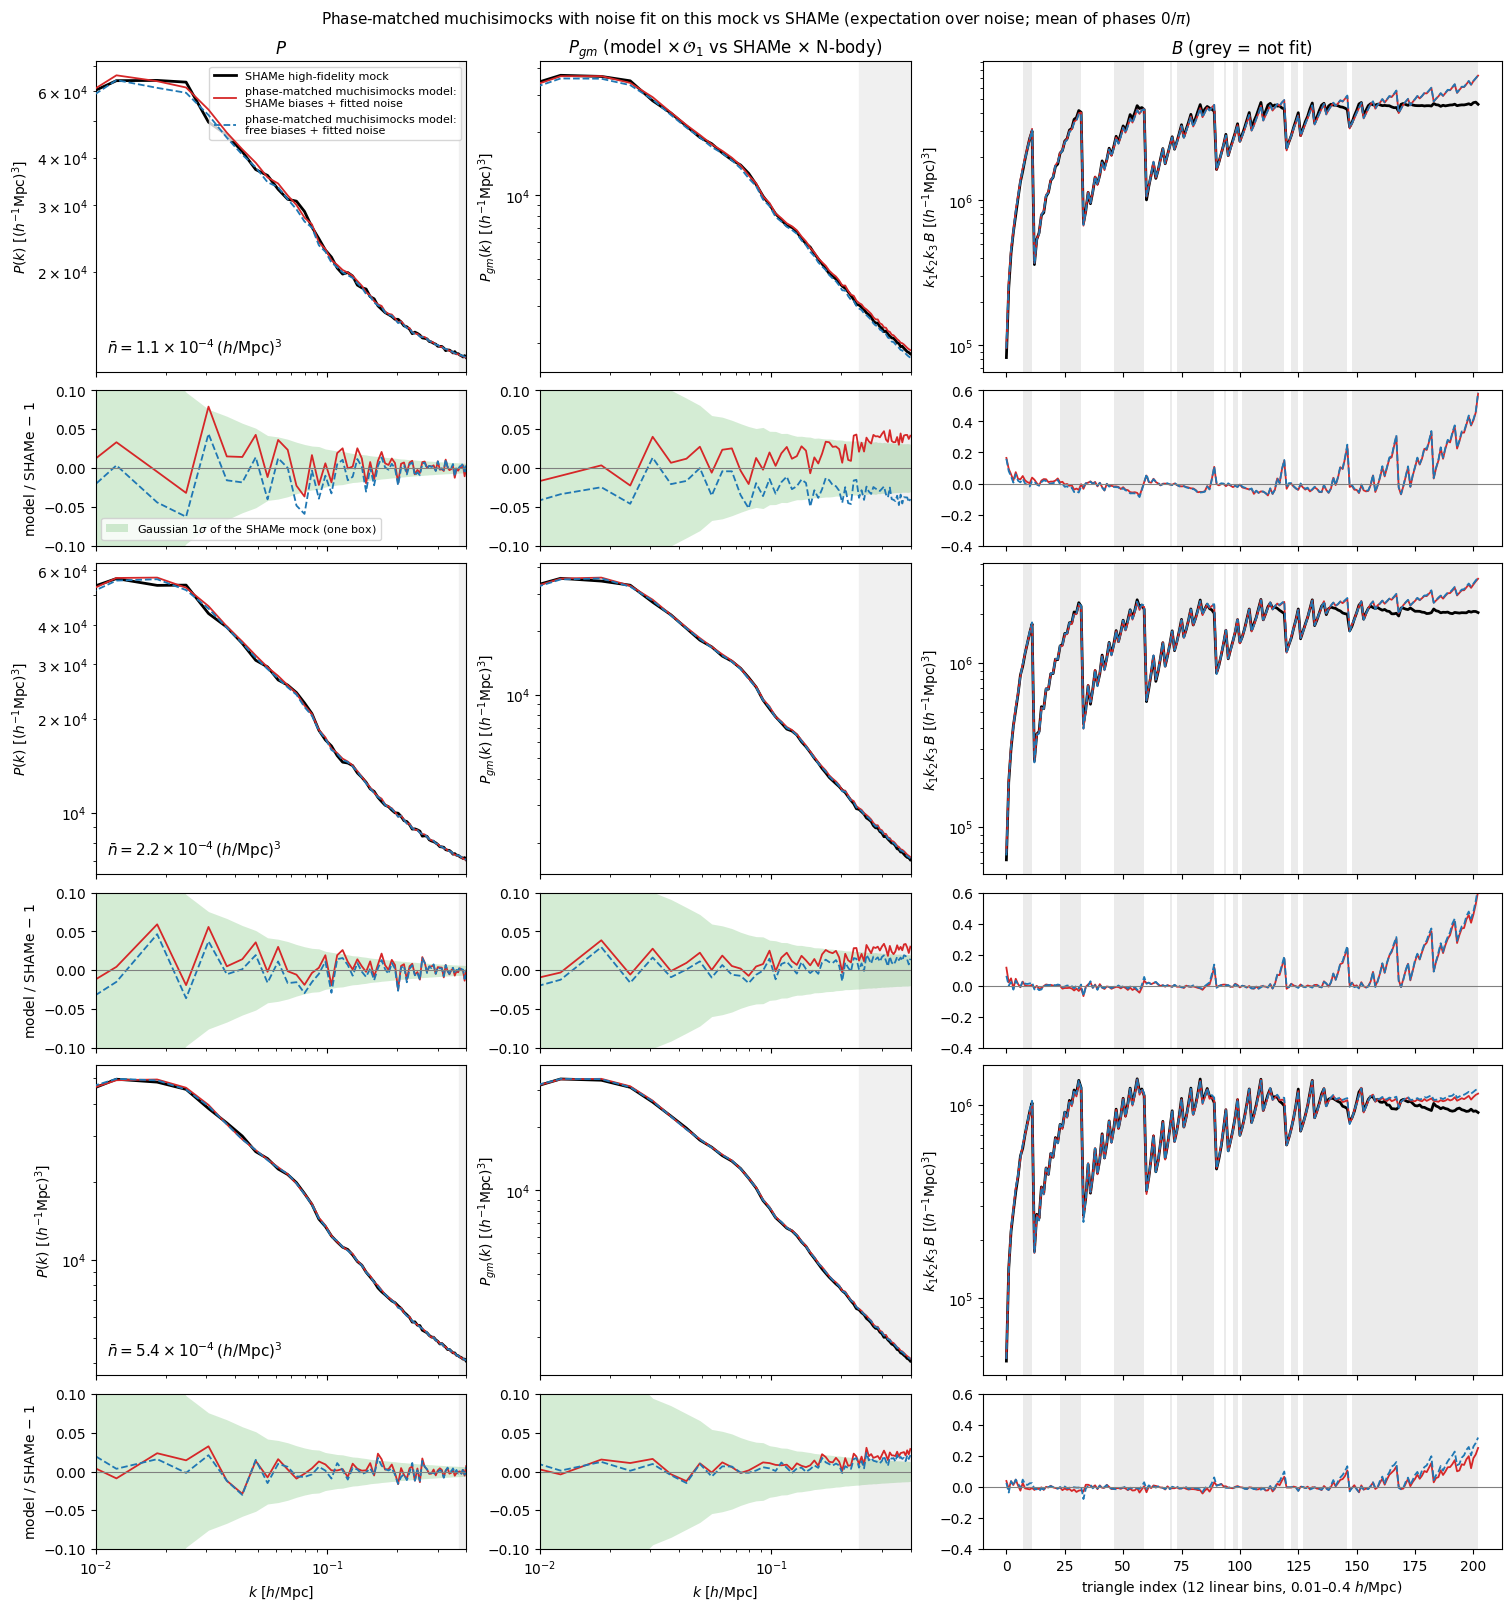

reduced chi2 (P, B: fit; Pgm vs O_1, not fit)   |model/SHAMe - 1| median/max: P 0.03<=k<=0.37, Pgm(vs N-body) 0.03<=k<=0.24, B k_i<0.25;  B max k_i>0.3: median, 90th pct
nbar     biases   chi2r P     B   Pgm             P         Pgm           B        B hi-k
1.1e-04 fixed b     0.56  1.20  2.64   0.008/0.079 0.020/0.043 0.012/0.165 +0.002, 0.308
1.1e-04 free b      0.59  0.78  0.13   0.006/0.059 0.023/0.052 0.008/0.159 -0.006, 0.317
2.2e-04 fixed b     0.56  0.47  4.39   0.006/0.056 0.013/0.029 0.009/0.117 +0.033, 0.335
2.2e-04 free b      0.47  0.45  2.63   0.006/0.037 0.009/0.017 0.010/0.065 +0.033, 0.352
5.4e-04 fixed b     0.35  0.41  7.99   0.004/0.032 0.009/0.023 0.009/0.048 +0.006, 0.130
5.4e-04 free b      0.28  0.39  6.39   0.004/0.030 0.006/0.018 0.008/0.077 +0.016, 0.188

production-pipeline check (_nbar0.00022, SHAMe biases, A x1.0106; median over 10 noise realizations of median/max):
  P                          0.008 / 0.069
  Pgm (O_1 vs SHAMe N-body)  0.014 / 0.040
  B

In [8]:
k_nb, k123_nb, msk_nb = fit_nb['k_pk'], fit_nb['k123'], fit_nb['masks']
assert np.allclose(k_nb, k_sh)
itri_nb = np.arange(k123_nb.shape[1])
kcut = {'pk': 0.37, 'pgm': 0.24}                    # v2 fiducial cuts

# SHAMe P_gm against the N-body matter, as in the SHAMe data vector (same dk = k_f binning as the fit)
pgm_sh_nbody = {t: np.mean([pk_sh(ft_sh(tr), ft_sh(dm)) for tr, dm in (load_shame_fields(ph, t) for ph in phases_sh)], axis=0)
                for t in tags_shame}

def target(t, stat):
    sh = fit_nb['targets'][t]
    return pgm_sh_nbody[t] if stat == 'pgm' else sh[stat]

def resid(t, s_, stat):
    return fit_nb['fits'][(t, s_)]['stats'][stat] / target(t, stat) - 1

# production-pipeline check of the test-set point (nbar = 2.2e-4, SHAMe biases), 10 noise realizations
nb_stats = np.load(msm.DIR_DATA_SHAME / f'matched_seed{SEED_SH}' / 'stats_noisebest.npy', allow_pickle=True).item()
tag_nb = nb_stats['tag_mock']
B_NORM = float(NG_SH)**9            # PolyBin Bk_ideal on delta/N^3 fields -> physical (load_bispec convention)
k_prod = nb_stats['0']['k']

def shame_stored(stat):
    # stored SHAMe data vectors (production estimators), pair mean
    d = [np.load(msm.DIR_DATA_SHAME / f'data{tag_nb}_phase{ph}' / f'{stat}s' / f'{stat}.npy', allow_pickle=True).item()
         for ph in phases_sh]
    return np.mean([x['bispectrum']['b0'] * B_NORM if stat == 'bispec' else x['pk'] for x in d], axis=0)

def prod_resid(stat):
    # (n_real, nbins): pair mean per noise realization, / SHAMe - 1
    get = {'pk': lambda d: d['pk'], 'pgm': lambda d: d['pgm']['m2m'], 'bispec': lambda d: d['bk'] * B_NORM}[stat]
    return 0.5 * (get(nb_stats['0']) + get(nb_stats['pi'])) / shame_stored(stat) - 1

cols_st = [('pk', r'$P(k)$ [$(h^{-1}$Mpc$)^3$]'),
           ('pgm', r'$P_{gm}(k)$ [$(h^{-1}$Mpc$)^3$]'),
           ('bk', r'$k_1k_2k_3\,B$ [$(h^{-1}$Mpc$)^3$]')]
k1k2k3_nb = np.prod(k123_nb, axis=0)
fig, axes = plt.subplots(6, 3, figsize=(15, 16), sharex='col', layout='constrained',
                         gridspec_kw=dict(height_ratios=[2, 1] * 3, width_ratios=[1, 1, 1.4]))
for i, t in enumerate(tags_shame):
    sh = fit_nb['targets'][t]
    for j, (stat, lab) in enumerate(cols_st):
        ax, axr = axes[2 * i, j], axes[2 * i + 1, j]
        x = itri_nb if stat == 'bk' else k_nb
        scale = k1k2k3_nb if stat == 'bk' else 1.0
        ax.plot(x, scale * target(t, stat), 'k', lw=2, label='SHAMe high-fidelity mock', zorder=5)
        for s_, (c, ls, _, slab_) in settings_nb.items():
            ax.plot(x, scale * fit_nb['fits'][(t, s_)]['stats'][stat], color=c, ls=ls, lw=1.3, label=slab_, zorder=6)
            axr.plot(x, resid(t, s_, stat), color=c, ls=ls, lw=1.3)
        if stat == 'bk':
            for a in (ax, axr):
                a.fill_between(itri_nb, 0, 1, where=~msk_nb['bk'], step='mid', color='0.92', lw=0, zorder=0,
                               transform=a.get_xaxis_transform())
            axr.set_ylim(-0.4, 0.6)
        else:
            sig = np.sqrt(sh['var'][stat]) / sh[stat]
            axr.fill_between(k_nb, -sig, sig, color='C2', alpha=0.2, lw=0, zorder=0, label=r'Gaussian $1\sigma$ of the SHAMe mock (one box)')
            for a in (ax, axr):
                a.axvspan(kcut[stat], 0.4, color='0.94', zorder=-1)
                a.set_xscale('log'); a.set_xlim(0.01, 0.4)
            axr.set_ylim(-0.1, 0.1)
        ax.set_yscale('log')
        axr.axhline(0, color='0.5', lw=0.8)
        ax.set_ylabel(lab)
        if j == 0:
            axr.set_ylabel('model / SHAMe $-$ 1')
            ax.text(0.03, 0.06, rf'$\bar n = {nbar_of[t] * 1e4:.1f}\times10^{{-4}}\,(h/\mathrm{{Mpc}})^3$',
                    transform=ax.transAxes, fontsize=11)
        if i == 0:
            ax.set_title({'pk': r'$P$', 'pgm': r'$P_{gm}$ (model $\times\,\mathcal{O}_1$ vs SHAMe $\times$ N-body)',
                          'bk': r'$B$ (grey = not fit)'}[stat])
for j, xl in enumerate([r'$k$ [$h$/Mpc]', r'$k$ [$h$/Mpc]', 'triangle index (12 linear bins, 0.01–0.4 $h$/Mpc)']):
    axes[-1, j].set_xlabel(xl)
axes[0, 0].legend(fontsize=8, loc='upper right'); axes[1, 0].legend(fontsize=8, loc='lower left')
fig.suptitle('Phase-matched muchisimocks with noise fit on this mock vs SHAMe (expectation over noise; mean of phases $0/\\pi$)', fontsize=11)
plt.show()

# summary: reduced chi2 of the fit, and |model / SHAMe - 1| within the fiducial cuts
mP = (k_nb >= 0.03) & (k_nb <= kcut['pk'])
mG = (k_nb >= 0.03) & (k_nb <= kcut['pgm'])
mBhi = k123_nb.max(axis=0) > 0.3
print('reduced chi2 (P, B: fit; Pgm vs O_1, not fit)   |model/SHAMe - 1| median/max: '
      f"P 0.03<=k<={kcut['pk']}, Pgm(vs N-body) 0.03<=k<={kcut['pgm']}, B k_i<0.25;  B max k_i>0.3: median, 90th pct")
print(f"{'nbar':8s} {'biases':8s} {'chi2r P':>7s} {'B':>5s} {'Pgm':>5s}   {'P':>11s} {'Pgm':>11s} {'B':>11s} {'B hi-k':>13s}")
for t in tags_shame:
    for s_ in settings_nb:
        c = fit_nb['fits'][(t, s_)]['chi2_red']
        rP, rG, rB = np.abs(resid(t, s_, 'pk')[mP]), np.abs(resid(t, s_, 'pgm')[mG]), resid(t, s_, 'bk')
        print(f"{nbar_of[t]:.1e} {s_:8s} {c['pk']:7.2f} {c['bk']:5.2f} {c['pgm']:5.2f}   "
              f"{np.median(rP):.3f}/{rP.max():.3f} {np.median(rG):.3f}/{rG.max():.3f} "
              f"{np.median(np.abs(rB[msk_nb['bk']])):.3f}/{np.abs(rB[msk_nb['bk']]).max():.3f} "
              f"{np.median(rB[mBhi]):+.3f}, {np.percentile(np.abs(rB[mBhi]), 90):.3f}")
mPp = (k_prod >= 0.03) & (k_prod <= kcut['pk']); mGp = (k_prod >= 0.03) & (k_prod <= kcut['pgm'])
print(f'\nproduction-pipeline check ({tag_nb}, SHAMe biases, A x{nb_stats["V_scale"]:.4f}; median over 10 noise realizations of median/max):')
for lab, stat, m in [('P', 'pk', mPp), ('Pgm (O_1 vs SHAMe N-body)', 'pgm', mGp), ('B k_i<0.25', 'bispec', msk_nb['bk'])]:
    r = np.abs(prod_resid(stat)[:, m])
    print(f'  {lab:26s} {np.median(np.median(r, axis=1)):.3f} / {np.median(r.max(axis=1)):.3f}')

**Conclusions, §2.3**

| $\bar n$ [$10^{-4}$] | biases | $\chi^2_\mathrm{red}$ $P$ / $B$ (fit) | $P$, $k\le0.37$ | $P_{gm}$ vs N-body, $k\le0.24$ | $B$, $k_i<0.25$ | $B$, $\max k_i>0.3$ (not fit): median, 90th pct |
|---|---|---|---|---|---|---|
| 1.1 | SHAMe | 0.56 / 1.20 | 0.8% / 7.9% | 2.0% / 4.3% | 1.2% / 17% | $+0\%$, 31% |
| | free | 0.59 / 0.78 | 0.6% / 5.9% | 2.3% / 5.2% | 0.8% / 16% | $-1\%$, 32% |
| 2.2 | SHAMe | 0.56 / 0.47 | 0.6% / 5.6% | 1.3% / 2.9% | 0.9% / 12% | $+3\%$, 34% |
| | free | 0.47 / 0.45 | 0.6% / 3.7% | 0.9% / 1.7% | 1.0% / 6.5% | $+3\%$, 35% |
| 5.4 | SHAMe | 0.35 / 0.41 | 0.4% / 3.2% | 0.9% / 2.3% | 0.9% / 4.8% | $+1\%$, 13% |
| | free | 0.28 / 0.39 | 0.4% / 3.0% | 0.6% / 1.8% | 0.8% / 7.7% | $+2\%$, 19% |

(median / max of $|\mathrm{model}/\mathrm{SHAMe}-1|$ over $0.03\le k$; max values in $P$ come from the few lowest-$k$ bins, where SHAMe's own shot-noise realization isn't matched.)

- **$P$ and $B$: the 5-amplitude noise model fits SHAMe at every density, with either bias choice.** Within the fiducial cuts the median residual is $<1\%$ for both, and the reduced $\chi^2$ is below 1 except $B$ at $1.1\times10^{-4}$ with SHAMe biases (1.2). Fixed and free biases are almost indistinguishable in $P$ and $B$, because the noise absorbs the difference.
- **$B$ beyond the cut.** Triangles with $k_i \gtrsim 0.3$ overshoot SHAMe, by up to $+50$–$60\%$ at the highest-$k$ triangles for the two lower densities and $\sim+30\%$ at $5.4\times10^{-4}$. This is outside the fiducial $B$ cut (0.24), and §2.5 shows no extra noise term fixes it.
- **$P_{gm}$ tests only the biases.** With SHAMe biases the model is $1$–$2\%$ high (median), rising to $+3$–$4\%$ near the cut. Free biases fit SHAMe's $P_{gm}$ against $\mathcal{O}_1$ much better at the lowest density ($\chi^2_\mathrm{red}$ 0.13 vs 2.6; at the other two densities 2.6 vs 4.4 and 6.4 vs 8.0), but against the N-body matter of the SHAMe data vector they're then $\sim4\%$ *low* at $1.1\times10^{-4}$. So at the few-percent level, $P_{gm}$ is limited by map2map vs. N-body matter, not by the bias values. (With the old ×2 SHAMe biases, $\chi^2_\mathrm{red}$ against $\mathcal{O}_1$ was 17.8, 17.5, 8.1.)
- **The production pipeline reproduces the fit** (test-set point at $2.2\times10^{-4}$, 10 noise realizations): median / max residual $0.8\%$ / $7\%$ in $P$, $1.4\%$ / $4\%$ in $P_{gm}$, $2.4\%$ / $16\%$ in $B$ ($k_i<0.25$). These are a bit larger than the fit's numbers because each realization has its own noise scatter, which the fit's expectation over the noise averages out.

### 2.4 Fitted noise amplitudes vs. density, and the priors

The amplitudes from the §2.3 fits, in library units ($A_\mathrm{matched}/1.011$), against the v2 noise priors (`_biasnoisenestv2`, set from these fits).

In [9]:
print(f"{'nbar':8s} {'biases':8s}  b1, b2, bs2, bl                  A: " + ', '.join(names_nb))
for t in tags_shame:
    for s_ in settings_nb:
        r = fit_nb['fits'][(t, s_)]
        print(f"{nbar_of[t]:.1e} {s_:8s}  {np.round(r['b'], 3)}   {np.round(r['A_lib'], 2)}")
print('\ncurrent priors on A:', bounds_nb)

nbar     biases    b1, b2, bs2, bl                  A: An_homog, An_b1, An_b2, An_bs2, An_bl
1.1e-04 fixed b   [ 0.529  0.069 -0.109 -1.07 ]   [ 2.44 -2.69  1.93 -1.65 -1.61]
1.1e-04 free b    [ 0.496  0.117 -0.051  0.64 ]   [ 2.28 -2.58  2.02 -1.8   2.53]
2.2e-04 fixed b   [ 0.474  0.032 -0.085 -0.824]   [ 2.02 -1.96  0.98 -0.67 -8.16]
2.2e-04 free b    [ 0.461  0.013 -0.086 -0.968]   [  1.53  -1.12   0.52   0.55 -11.51]
5.4e-04 fixed b   [ 0.402 -0.005 -0.048 -0.792]   [ 0.01  0.1   0.42 -1.98  9.2 ]
5.4e-04 free b    [ 0.392 -0.036 -0.056 -1.175]   [ 0.   -0.82  0.31 -0.45  3.78]

current priors on A: {'An_homog': (-5.0, 5.0), 'An_b1': (-5.0, 5.0), 'An_b2': (-3.0, 3.0), 'An_bs2': (-5.0, 5.0), 'An_bl': (-20.0, 20.0)}


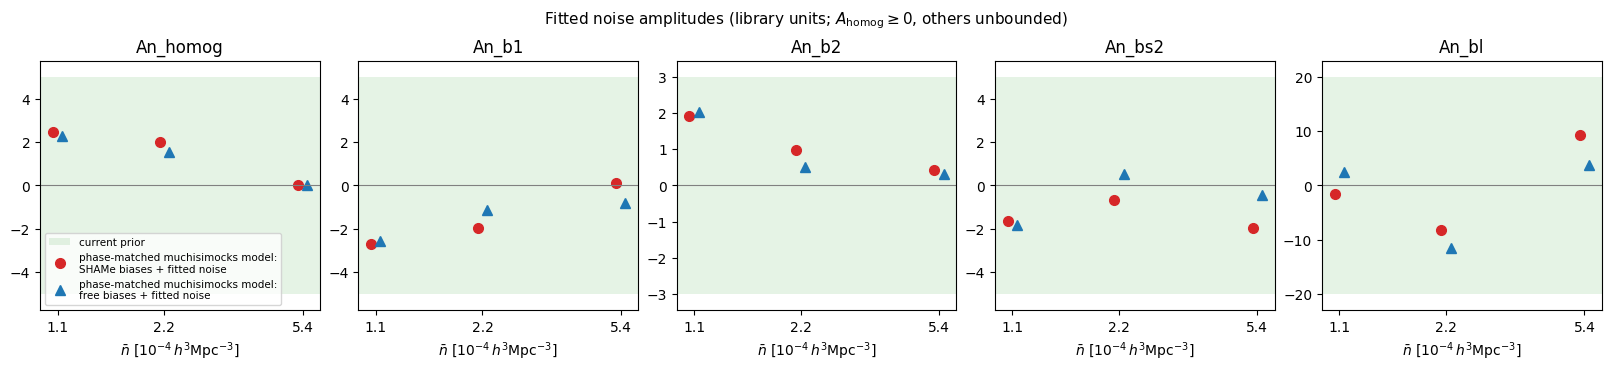

In [10]:
# Figure 2: fitted amplitudes vs density, with the current prior range
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6), sharex=True, layout='constrained')
x_nb = np.array([nbar_of[t] for t in tags_shame])
for j, n in enumerate(names_nb):
    ax = axes[j]
    lo, hi = bounds_nb[n]
    ax.axhspan(lo, hi, color='C2', alpha=0.12, lw=0, label='current prior' if j == 0 else None)
    for k_, (s_, (c, _, mk, lab)) in enumerate(settings_nb.items()):
        y = [fit_nb['fits'][(t, s_)]['A_lib'][j] for t in tags_shame]
        ax.plot(x_nb * (1 + 0.06 * (k_ - 0.5)), y, color=c, marker=mk, ls='none', ms=7, label=lab if j == 0 else None)
    ax.axhline(0, color='0.5', lw=0.8)
    ax.set_xscale('log'); ax.set_title(n); ax.set_xlabel(r'$\bar n$ [$10^{-4}\,h^3$Mpc$^{-3}$]')
    ax.set_xticks(x_nb, [f'{v * 1e4:.1f}' for v in x_nb], minor=False); ax.set_xticks([], minor=True)
    ymax = max(abs(lo), abs(hi), *[abs(fit_nb['fits'][(t, s_)]['A_lib'][j]) for t in tags_shame for s_ in settings_nb])
    ax.set_ylim(-1.15 * ymax, 1.15 * ymax)
axes[0].legend(fontsize=7.5, loc='lower left')
fig.suptitle(r'Fitted noise amplitudes (library units; $A_\mathrm{homog}\geq0$, others unbounded)', fontsize=11)
plt.show()

**Conclusions, §2.4**

Largest $|A|$ over all 6 fits:

| | largest $\lvert A\rvert$ (where) | v2 prior |
|---|---|---|
| `An_homog` | 2.44 (1.1e-4, fixed) | ±5 |
| `An_b1` | 2.69 (1.1e-4, fixed) | ±5 |
| `An_b2` | 2.02 (1.1e-4, free) | ±3 |
| `An_bs2` | 1.98 (5.4e-4, fixed) | ±5 |
| `An_bl` | 11.5 (2.2e-4, free) | ±20 |

- **Don't restrict the sign of `An_homog`.** At $5.4\times10^{-4}$ it goes to its floor of 0 for both bias choices, and the $\epsilon\,\mathcal{O}_\delta$ and $\epsilon\nabla^2\delta$ terms carry the noise instead. A prior cut at 0 would pile the posterior against the edge for dense tracers. No other amplitude stays clearly away from 0 either (`An_bl` changes sign between densities), so the sign symmetry can't be removed with a simple bound.
- **The amplitudes are strongly degenerate.** Freeing the biases moves `An_bl` by several units at almost the same $\chi^2$. So the table is a guide to how wide the priors must be, not a set of physical values.

### 2.5 Can an extra $\epsilon^2$ noise term fix $B$? (fit on the matched mock, no cosmic variance)

The old best-fit noise points (`noisebest` before 2026-11-15, `noisem2best`) were each picked as the best of 1000 library mocks that all have **different** initial conditions, so the pick partly selected a lucky cosmic-variance fluctuation. (`noisebest` is now refit on the matched mock instead, §2.3.) Here I refit the noise amplitudes directly on the phase-matched mock, where there is no cosmic variance to exploit, and ask which noise terms are needed to match SHAMe's $P$ and $B$ together.

**Setup** (coefficients: `code_auxiliary/compute_shame_matched_noisepoly.py`, Slurm `code_auxiliary/jobs/job_shame_matched_noisepoly.s`, ~45 min; fits: `code_auxiliary/fit_shame_matched_noisepoly.py`, ~1 min, run on a login node). $\bar n = 2.2\times10^{-4}$; biases fixed at the field-level fit (phase mean, §2b), so the deterministic part is as good as it gets. The tracer is linear in the noise amplitudes,
$$\delta_t = \delta_\mathrm{det} + \sum_{i=1}^{5} A_i\,\epsilon\,\mathcal{O}_i \;+\; A^{(2)}_{1}\,(\epsilon^2-1)\,\mathcal{O}_1 \;+\; A^{(2)}_{\nabla^2}\,(\epsilon^2-1)\,\mathcal{O}_{\nabla^2\delta},$$
so $P$ is exactly quadratic and $B$ exactly cubic in the $A$'s. The job computes those coefficients once (2 noise realizations × 2 phases; the cubic fit reproduces held-out $B$ evaluations to $10^{-13}$), and every fit below is then instant. I use $\epsilon^2-1$ rather than the production $\epsilon^2$: the mean part of $\epsilon^2$ only rescales the $\mathcal{O}_1$ term, which free biases would absorb anyway.

**Fit:** minimize $\langle(P/P_\mathrm{SHAMe}-1)^2\rangle_{0.03\le k\le0.35} + \langle(B/B_\mathrm{SHAMe}-1)^2\rangle_{k_i<0.25}$ (equal weight per probe, fractional residuals, 10 random L-BFGS starts; models containing the 5-param one also start from its solution), against the raw SHAMe $P$ and $B$ (all stochasticity comes from the noise terms, as in the library mocks). Triangles with $k_i \ge 0.25$ are not fit, so they show how well each model extrapolates.

Models compared: $\epsilon$ terms only (the paper's 5-parameter model), plus each $\epsilon^2$ term on its own, and the production m2p3 basis ($\epsilon\mathcal{O}_1$, $\epsilon^2\mathcal{O}_1$, $\epsilon^2\mathcal{O}_{\nabla^2\delta}$).

In [11]:
# Fits are done by code_auxiliary/fit_shame_matched_noisepoly.py (~1 min); this cell only loads them.
fits_np = np.load(msm.DIR_DATA_SHAME / f'matched_seed{SEED_SH}' / 'noise_poly_fits.npy', allow_pickle=True).item()
k_p, mP, mB, mB_hi = fits_np['k_pk'], fits_np['mP'], fits_np['mB'], fits_np['mB_hi']
P_sh, B_sh, models_np, labels_np = fits_np['P_sh'], fits_np['B_sh'], fits_np['models'], fits_np['labels']
print('biases (field-level fit):', np.round(fits_np['b'], 3))

print(f"\n{'model':14s} {'loss':>8s}  {'P med/max':>12s}  {'B(k<0.25) med/max':>18s}  {'B(k>0.3) med, 90%':>18s}  {'held-out loss':>16s}")
for name, m in models_np.items():
    print(f"{name:14s} {m['loss']:8.1e}  {m['P_med']:5.3f}/{m['P_max']:5.3f}  {m['B_med']:8.3f}/{m['B_max']:5.3f}"
          f"     {m['B_hi_med']:+.3f}, {m['B_hi_90']:.3f}   {m['loss_holdout'][0]:.1e}->{m['loss_holdout'][1]:.1e}")
print('\nbest-fit A:', fits_np['comp_names'][1:])
for name, m in models_np.items():
    print(f'  {name:14s}', np.round(m['A'], 3))

# where does B come from? split by order in the noise amplitudes (median over triangles, / B_SHAMe)
groups_t = {'k_i<0.15': fits_np['k123'].max(0) < 0.15, 'k_i<0.25': mB, 'max k_i>0.3': mB_hi}
nbar_t = 2.2e-4
print('\nB split by order in A  (median of term / B_SHAMe)')
for name in ['eps', 'eps+eps2_lapl']:
    print(f'  {name}')
    for d, lab in enumerate(['A^0  deterministic', 'A^1  noise x det x det', 'A^2  noise x noise x det', 'A^3  noise^3']):
        o = models_np[name]['B_order'][d]
        print(f'    {lab:26s}' + ''.join(f'{g}: {np.median(o[m] / B_sh[m]):+.3f}   ' for g, m in groups_t.items()))
print('  Poisson 1/nbar^2 for scale' + ''.join(f'  {g}: {np.median(1 / nbar_t**2 / B_sh[m]):.3f} ' for g, m in groups_t.items()))

biases (field-level fit): [ 0.457  0.011 -0.068 -0.234]

model              loss     P med/max   B(k<0.25) med/max   B(k>0.3) med, 90%     held-out loss
none            3.5e-01  0.424/0.587     0.405/0.560     -0.579, 0.631   3.5e-01->3.5e-01
eps             3.8e-04  0.007/0.029     0.009/0.037     +0.007, 0.272   5.7e-04->1.4e-03
eps+eps2_O1     3.9e-04  0.008/0.031     0.010/0.034     +0.047, 0.420   5.3e-04->1.6e-03
eps+eps2_lapl   3.5e-04  0.008/0.029     0.008/0.031     +0.048, 0.416   5.7e-04->1.4e-03
m2p3            3.9e-04  0.007/0.035     0.008/0.049     +0.042, 0.387   7.9e-04->3.1e-03

best-fit A: ['eps*O1', 'eps*delta', 'eps*delta2', 'eps*s2', 'eps*lapl', '(eps2-1)*O1', '(eps2-1)*lapl']
  none           [0. 0. 0. 0. 0. 0. 0.]
  eps            [-1.907  3.12  -0.376  1.209  6.535  0.     0.   ]
  eps+eps2_O1    [ 0.469  1.098 -0.671  2.026 -5.251  0.351  0.   ]
  eps+eps2_lapl  [ 0.67   0.706 -0.389  1.332 -4.17   0.    -6.701]
  m2p3           [ 1.122  0.     0.     0.     0

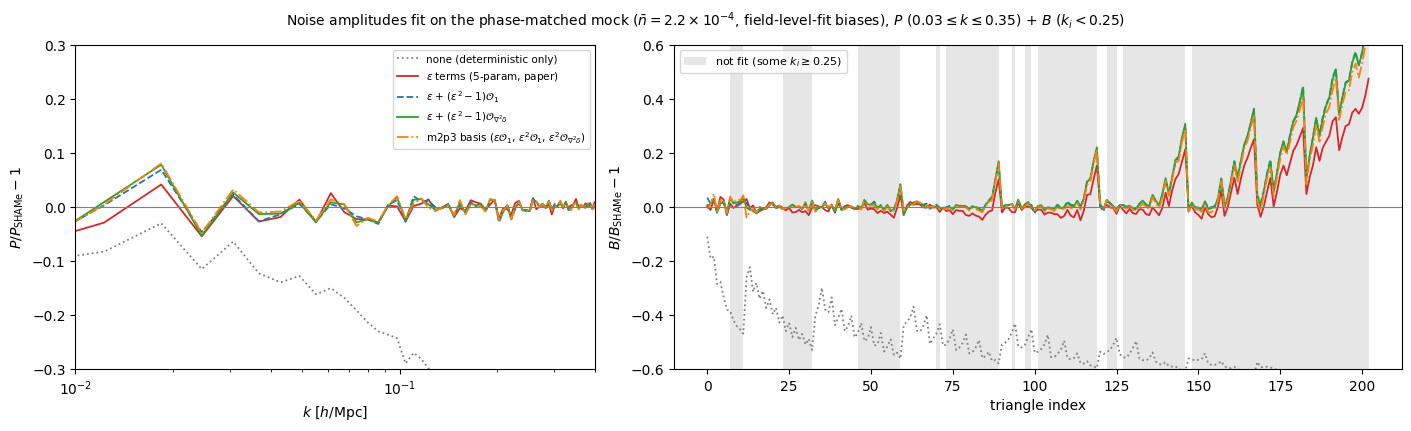

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw=dict(width_ratios=[1, 1.4]), layout='constrained')
style_nm = {'none': ('0.5', ':'), 'eps': ('C3', '-'), 'eps+eps2_O1': ('C0', '--'),
            'eps+eps2_lapl': ('C2', '-'), 'm2p3': ('C1', '-.')}
itri_p = np.arange(len(mB))
axes[1].fill_between(itri_p, -1, 1, where=~mB, step='mid', color='0.9', lw=0, zorder=0,
                     label=r'not fit (some $k_i \geq 0.25$)')
for name, m in models_np.items():
    c, ls = style_nm[name]
    axes[0].plot(k_p, m['P'] / P_sh - 1, color=c, ls=ls, lw=1.3, label=labels_np[name])
    axes[1].plot(itri_p, m['B'] / B_sh - 1, color=c, ls=ls, lw=1.3)
axes[0].set_xscale('log'); axes[0].set_xlim(0.01, 0.4); axes[0].set_ylim(-0.3, 0.3)
axes[0].set_xlabel(r'$k$ [$h$/Mpc]'); axes[0].set_ylabel(r'$P/P_\mathrm{SHAMe} - 1$')
axes[1].set_ylim(-0.6, 0.6)
axes[1].set_xlabel('triangle index'); axes[1].set_ylabel(r'$B/B_\mathrm{SHAMe} - 1$')
for ax in axes:
    ax.axhline(0, color='0.5', lw=0.8)
axes[0].legend(fontsize=7.5); axes[1].legend(fontsize=8, loc='upper left')
fig.suptitle(r'Noise amplitudes fit on the phase-matched mock ($\bar n=2.2\times10^{-4}$, field-level-fit biases), $P$ ($0.03\leq k\leq0.35$) + $B$ ($k_i<0.25$)', fontsize=10)
plt.show()

**Conclusions, §2.5** ($\bar n=2.2\times10^{-4}$, field-level-fit biases; $|\mathrm{model}/\mathrm{SHAMe}-1|$, median / max):

| noise terms | $P$ ($0.03$–$0.35$) | $B$ (fit, $k_i<0.25$) | $B$, $\max k_i>0.3$ (not fit): median, 90th pct of $\lvert\cdot\rvert$ |
|---|---|---|---|
| none | 42% / 59% | 41% / 56% | $-58\%$, 63% |
| $\epsilon$ (5-param, paper) | **0.7% / 2.9%** | **0.9% / 3.7%** | $+1\%$, 27% |
| + $(\epsilon^2-1)\mathcal{O}_1$ | 0.7% / 2.9% | 0.9% / 3.6% | $+1\%$, 29% |
| + $(\epsilon^2-1)\mathcal{O}_{\nabla^2\delta}$ | 0.8% / 2.9% | 0.8% / 3.1% | $+5\%$, 42% |
| m2p3 basis | 0.7% / 3.5% | 0.8% / 4.9% | $+4\%$, 39% |

- **The 5-parameter Gaussian noise model already fits $P$ and $B$ together to $<1\%$ (median), $\lesssim4\%$ (max), once its amplitudes are fit without cosmic variance.** Adding an $\epsilon^2$ term doesn't help: $(\epsilon^2-1)\mathcal{O}_1$ is driven to $\approx0$, and $(\epsilon^2-1)\mathcal{O}_{\nabla^2\delta}$ only trades between amplitudes (loss $3.8\to3.5\times10^{-4}$) while extrapolating *worse* to $k_i>0.3$.
- **Why the extra term isn't needed:** splitting $B$ by order in the amplitudes, SHAMe's stochastic $B$ (about 30–60% of the total) is almost entirely the **noise × noise × density** term ($\propto A^2$), e.g. $\langle(\epsilon\mathcal{O}_i)(\epsilon\mathcal{O}_j)\,\delta\rangle$: the noise variance is modulated by the density field, which is the same physics as Poisson's $(P_1+P_2+P_3)/\bar n$ term. The Gaussian model has this, with 15 amplitude products to shape it. The pure noise³ term that needs $\langle\epsilon^3\rangle\neq0$ (the analogue of Poisson's $1/\bar n^2$) is small on our scales: Poisson's $1/\bar n^2$ is only 2.5–6% of SHAMe's $B$ for $k_i<0.25$, and SHAMe is sub-Poisson. Adding $\epsilon^2$ terms does produce a noise³ part (5% at $k_i<0.25$, 14% at $k_i>0.3$), but the fit doesn't need it.
- **So $B$ needs no extra noise term.** An earlier $B$ mismatch of the test-set configuration came from the configuration (×2 biases plus noise amplitudes chosen on a cosmic-variance realization), and is gone with the ÷2 SHAMe biases and noise refit on the matched mock (§2.3). With free biases and noise, as in the inference, the model has enough freedom to describe SHAMe's 3-point stochasticity on the scales we use.
- **Beyond the fit range ($k_i\gtrsim0.3$) every model overshoots** for some high-$k$ triangles (up to $+50\%$; 90th percentile 27–42%). This is outside our $B$ cut of 0.25.
- **Caveats:** the amplitudes are strongly degenerate (e.g. $A_{\nabla^2}$ flips from $+6.5$ to $-4.2$ when the $\epsilon^2\mathcal{O}_{\nabla^2\delta}$ term is added, at nearly the same loss), so individual best-fit values shouldn't be read physically. Fitting on one noise realization and testing on the other raises the loss from $\sim5\times10^{-4}$ to $\sim1.5\times10^{-3}$ (rms residual $\sim2$–$3\%$), i.e. part of the sub-percent fit is tuning to the specific $\epsilon$; this is the same for every model, so the comparison between models stands. Biases were held fixed at the field-level fit; with biases free too the fits could only improve. One density only.